In [10]:
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt


In [11]:
# target() calculates prob of given sample x -> calculates the numerator term of prob density equation
def target(x):
    return np.exp(-x**2) * (2 + np.sin(5 * x) + np.sin(2 * x))

In [12]:
# metropolis_step() takes some value x (current Markov Chain state) and sigma parameter -> standard deviation of proposal distribution
# computes the accept-reject step for the x value and calcuates whether accepted or not.
# this function is called repeatedly from metropolis_sampler function below
def metropolis_step(x, sigma):
    proposed_x = np.random.normal(loc=x, scale=sigma)
    accept_prob = min(1, target(proposed_x) / target(x))
    u = np.random.rand()
    if u <= accept_prob:
        return proposed_x, True
    else:
        return x, False


In [13]:
def metropolis_sampler(initial_value, n=10000, sigma=1, burnin=0, lag=1):
    values = []
    accepted_flags = []
    current_state = initial_value # start point of Markov Chain

    for step in range(burnin): #burnin - number of interations before an accepted value removed
        current_state, appected = metropolis_step(current_state, sigma)

    for step in range(n):
        for step in range(lag): #lag - number of interations after an accepted value recorded
            current_state, accepted = metropolis_step(current_state, sigma)
        values.append(current_state)
        accepted_flags.append(accepted)

    return pd.DataFrame({'value': values, 'accepted': accepted_flags})


In [14]:
np.random.seed(1234)
import random
random.seed(1234)
results = metropolis_sampler(initial_value=0, n=10, sigma=0.1)
print(results) #show what data looks like before plotting

      value  accepted
0  0.047144      True
1  0.047144     False
2 -0.024915      True
3  0.063801      True
4  0.065371      True
5  0.065371     False
6  0.160703      True
7 -0.041422      True
8 -0.000877      True
9  0.028032      True


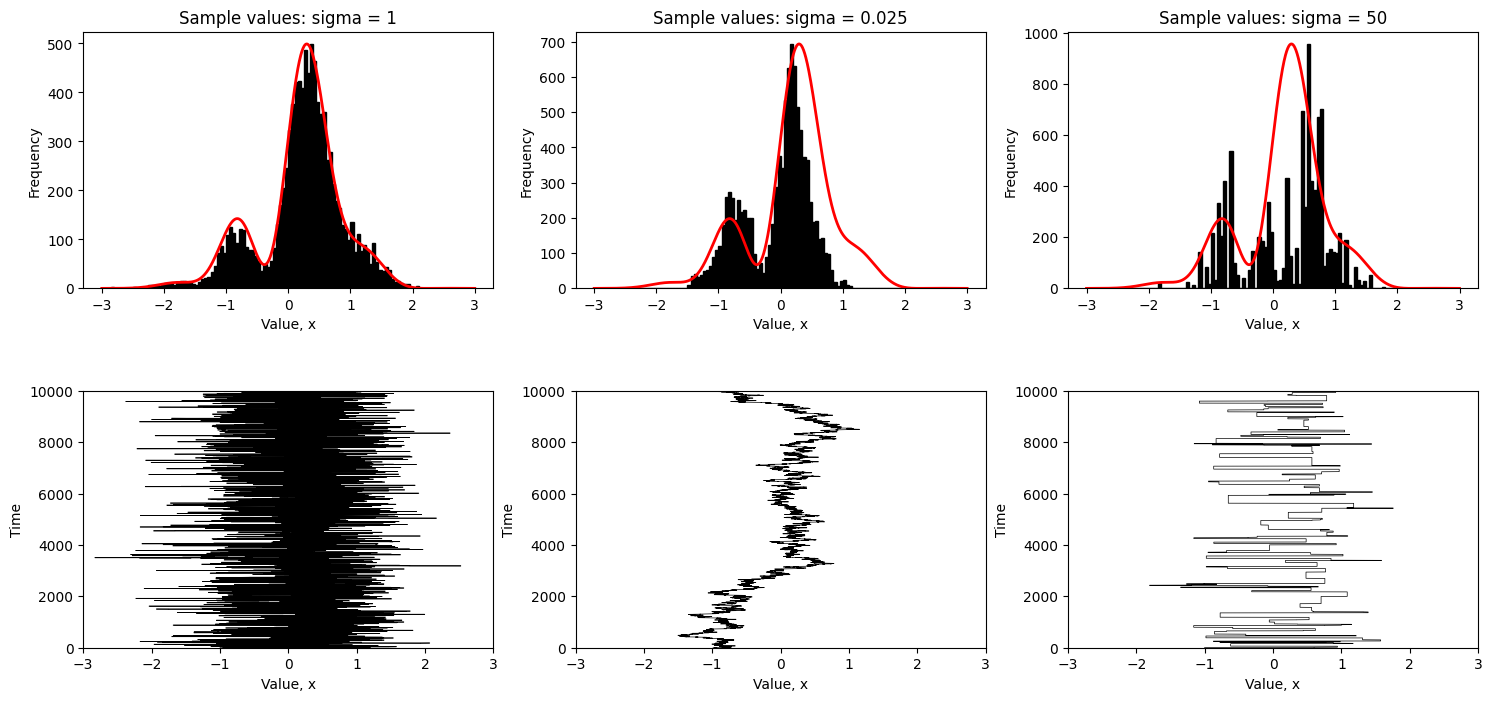

In [15]:
# Plotting
sigma_values = [1, 0.025, 50]
n = 10000
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
plt.subplots_adjust(hspace=0.4)

x_range = np.linspace(-3, 3, 1000)

for i, sigma in enumerate(sigma_values):
    out = metropolis_sampler(initial_value=-1, n=n, sigma=sigma)
    values = out['value']

    # Top row: histogram + actual line
    ax1 = axes[0, i]
    counts, bins, _ = ax1.hist(values, bins=np.arange(-3, 3, 0.05),
                               color='black', edgecolor='black')

    p = target(x_range)
    p_scaled = p * max(counts) / max(p)
    ax1.plot(x_range, p_scaled, 'r-', linewidth=2)

    ax1.set_title(f'Sample values: sigma = {sigma}')
    ax1.set_xlabel('Value, x')
    ax1.set_ylabel('Frequency')

    # Bottom row: trace plot
    ax2 = axes[1, i]
    ax2.plot(values, values.index, 'k-', linewidth=0.5)
    ax2.set_ylim(0, n)
    ax2.set_xlim(-3, 3)
    ax2.set_ylabel('Time')
    ax2.set_xlabel('Value, x')

plt.show()


In [7]:
x1 = int(input("Enter x1: "))
y1 = int(input("Enter y1: "))
x2 = int(input("Enter x2: "))
y2 = int(input("Enter y2: "))
taxi_distance = math.fabs(((x1-x2)+(y1-y2)))

Enter x1: 1
Enter y1: 3
Enter x2: 4
Enter y2: 8


In [8]:
def target(x):
    return taxi_distance

In [9]:
print(target(taxi_distance))

8.0
